# Final Project
## Computational Quantum Dynamics
### A Numerical Analysis of the Time-Dependent Schrödinger Equation

I tested four solvers (Forward Euler, Visscher Leapfrog, Crank–Nicolson, and FFT Split-Operator) to see what is the best one to truly utilize for all my simultations and then use that very one to generate computational solutions via simulations of three varied models.

# Part I | Stress Testing

Before doing any physics, I wanted to ensure the solver actually works. This part is simply controlled tests that I know what the expected results should be, so I have a reference as to what is and is not useable for my work. If the CFL bound is sharp, and/or if either total energy and/or probability is not conservered then I know the solver utilized it must be improperly implemented and must be dismissed. These are the baseline, the foundation of what determines if physical modeling is trustworthy or not.

## I.1 | Forward Euler (FTCS)
FTCS: Forward in time and centered in space.\
\
**Expectation:** Von Neumann analysis within the textbook says $|g|>1$ for every Fourier mode, so the norm (probability) should blow up no matter how small I pick $\Delta t$. I ran a free Gaussian for 400 steps to see the severity of the damages.

**Figure I.1.** Forward Euler norm vs. time on a free Gaussian (semilog $y$).

![Figure I.1. Forward-Euler (FTCS) instability for a free Gaussian wave packet on a 1201-point grid.  The semilog-y axis spans 80 orders of magnitude over 400 timesteps — well past floating-point overflow — confirming the von-Neumann prediction $|g|>1$ for every non-trivial Fourier mode.](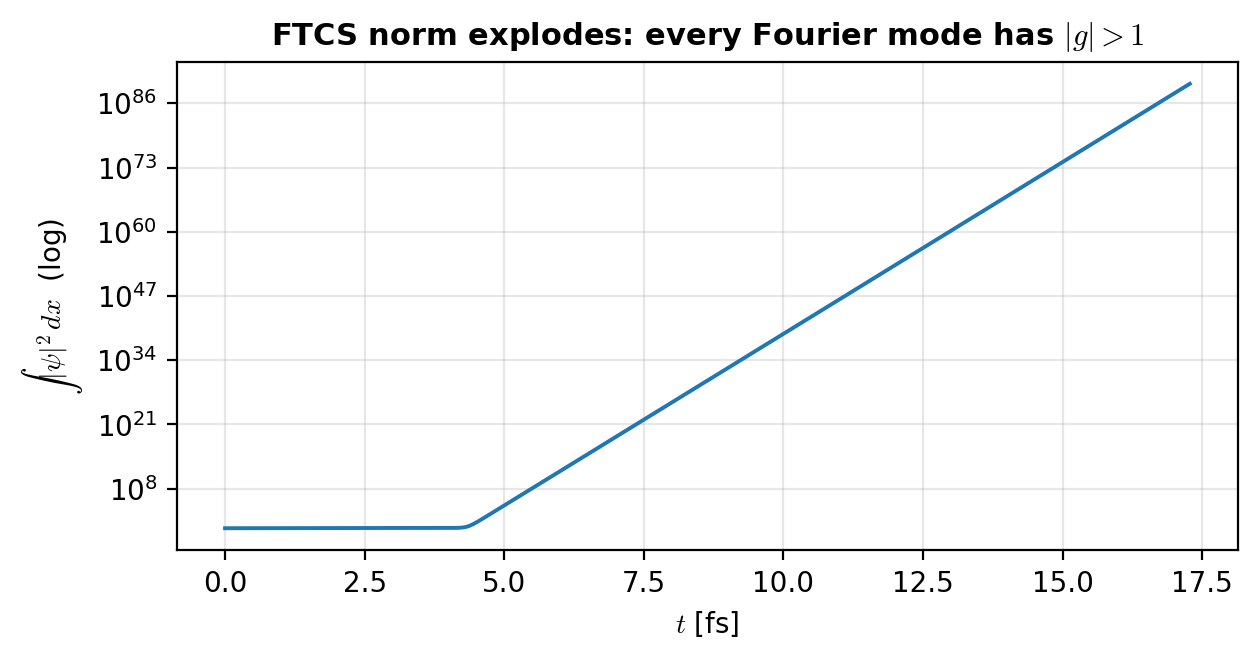)

**Results:** The probability which should always be equal to one (100%) as it is normalized (norm). The norm blew up by +80 orders of magnitude which is far faster than I expected.

**Logic:** The highest $k$ mode has the largest $|g|$, so it amplifies the fastest compared to lower eignenstates (lower energies). Numerical errors occur drastically similar to how the CFL bound blows up when broken.

**Checks:** With halving the time step ($\Delta t$), FTCS still blows up (just a "bit" later). This is a indicator of real instability that is unconditional. I then ran the same initial condition through Crank-Nicolson and the norm stayed constant. So the problem really is the integrator itself, sorry Euler.

So forward Euler is out. Switching to Visscher leapfrog from here with Crank-Nicolson and FFT as backups as Visscher is the recommended solver for the time-dependent Schrödinger equation in the textbook (chapter 22 I believe).

## I.2 | Visscher's Modified Norm

Visscher's leapfrog conversed probability, $\mathcal N$, but with a unique method by staggering the leapfrog. So, literally the space grid is shared amoungst the wave function's real and imaginary componets, but the time grid is not. There are two time grids, one for each componet where the real starts at $t=0$ and the imaginary starts at $t=\Delta t / 2$ (half a time step). The ordinary norm is without a staggered leapfrog, $\int|\psi|^2$, so it wobbles at $O(\Delta t^2)$.

**Expected:** $\mathcal N_{Visscher}$ flat at machine precision. Ordinary norm ($\mathcal N_{ord}$) wobbling around with the Crank-Nicolson norm flat as well. If anything *drifts* instead of wobbling, I have a real problem.

**Figure I.2.** Norm-conservation diagnostics on a free Gaussian: leapfrog ordinary norm, leapfrog modified $\mathcal N$, and Crank–Nicolson ordinary norm.

![Figure I.2.  Norm conservation diagnostics on a free Gaussian wave packet, three norms × two solvers.  *Left:* signed deviation from the starting value, on a linear scale.  *Right:* absolute deviation, on a log scale, with the machine-$\varepsilon$ floor marked.  The dashed red Visscher curve and the dotted green Crank–Nicolson curve are flat at machine precision; the solid blue ordinary-norm curve oscillates at $O(\Delta t^2)$.](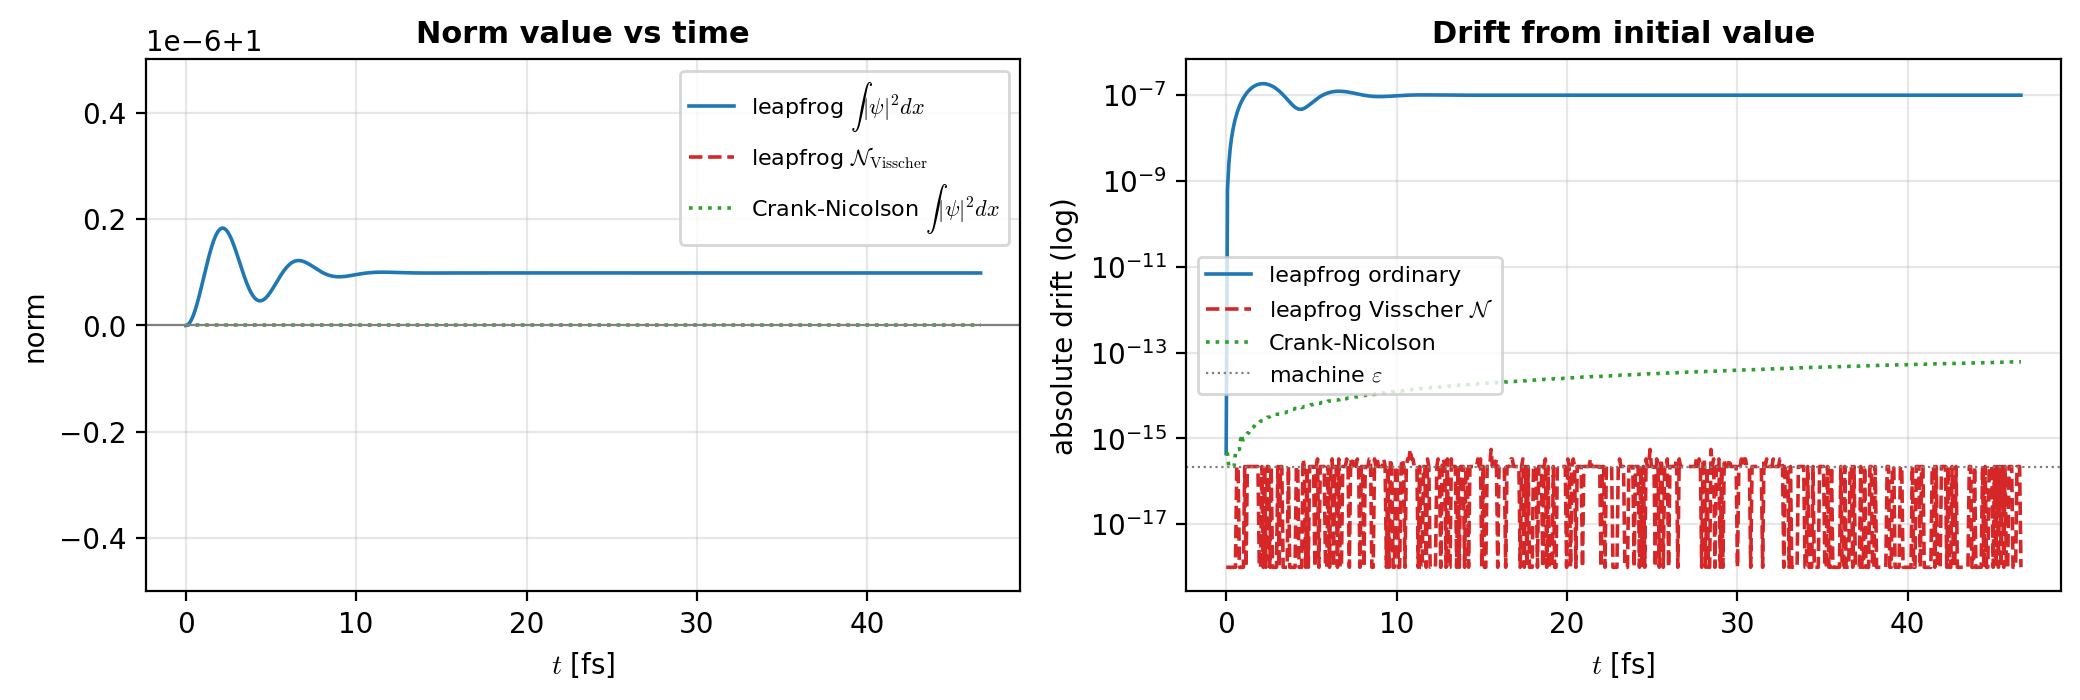)

**Results:** All three predictions held reasonably, but there are clear good and bad options. Visscher norm flat at $\sim 10^{-15}$ precision while the ordinary norm wobbles at $\sim 10^{-7}$ (converges) and bounded without any drifting. Crank-Nicolson norm is flat at $\sim 10^{-14}$ precision.

**Logic:** Crank-Nicolson is working but is not applied correctly (implicit methods should not be applied to wave problems). Visccher works incredibly well to near machine precision of $\sim 10^{-16}$ and the ordinary norm is not sufficient for long time interval problems and/or highly physical problems (simulations where major dynamics occur).

**Check:.** If $\mathcal N$ were just sitting at zero by coincidence, breaking Hermiticity should make it leak. In better terms, if the Hamiltonian operator (total energy) is not equal to it's own complex conjugate, then there is failure occuring in the numerical mathmatics.

## I.3 | Is the CFL bound strict?

Although this was performed in class before, checking once again is never a bad check. The CFL bound for leapfrog is $\Delta t_{\rm crit} = \hbar/(\tfrac12 V_{\max} + 2T)$. The question is whether it's a *sharp* cliff or a *soft* one. I ran the same Gaussian wave packet at $0.50$, $0.95$, $1.02$, and $1.10$ times $\Delta t_{\rm crit}$.

**Expectation::** The values under 1 stay flat with no uncertainty while the last two blow up near instantaneuously. The interesting bit is *how* sharply the transition happens which determines if being near 1 is justifyable or not.

**Figure I.3.** Same free Gaussian, four different timesteps: $0.50\,\Delta t_{\rm crit}$, $0.95\,\Delta t_{\rm crit}$, $1.02\,\Delta t_{\rm crit}$, $1.10\,\Delta t_{\rm crit}$.

![Figure I.3.  Sharpness of the leapfrog CFL bound.  Four runs of the same free Gaussian on the same grid, differing only in the safety factor on $\Delta t$.  Below the bound (0.50× and 0.95×) the norm stays flat for the entire 60 fs run.  Two percent above the bound, the norm grows by 10 orders of magnitude; ten percent above, by many tens of orders.](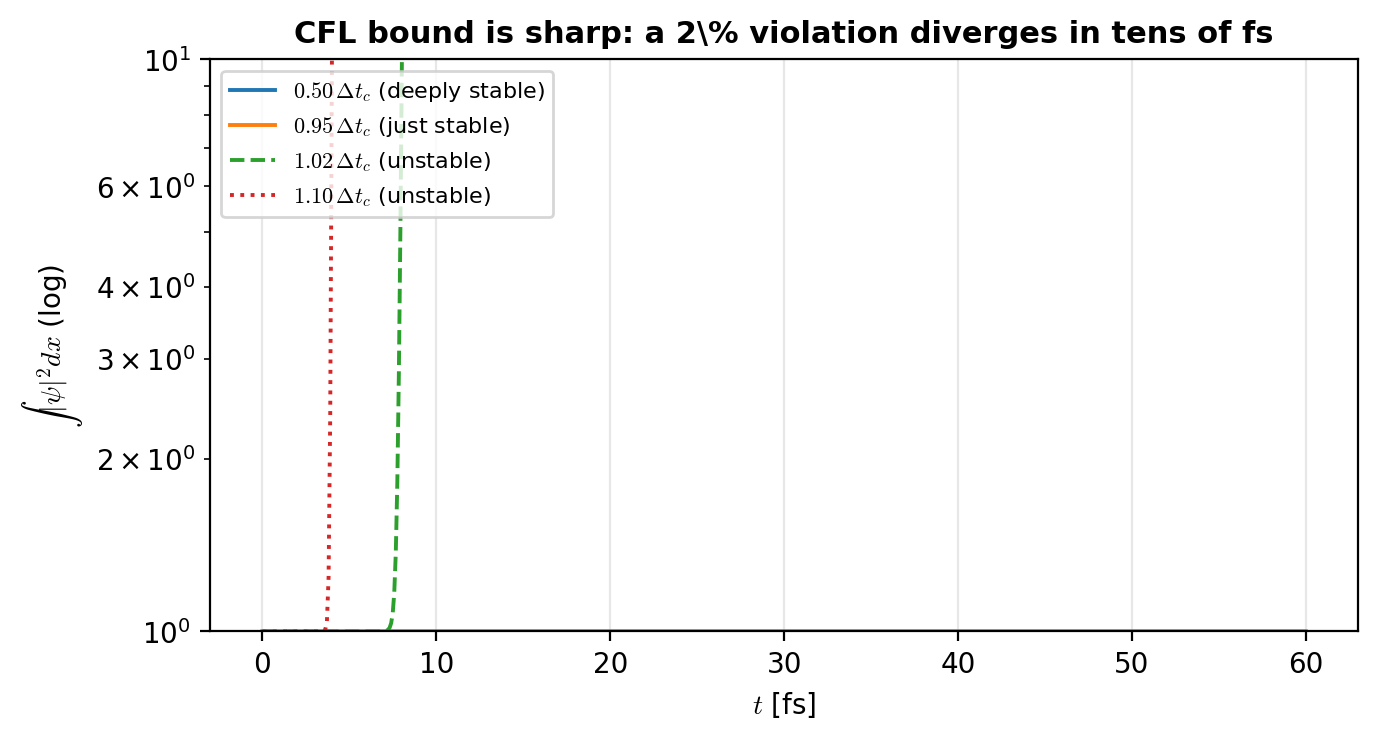)

**Results:** Sharp as I expected since this was done previously in class before with 0.50 and 0.95 are indistinguishable are they are  both flat (constant). At *1.02* the norm grows by ten decades in tens of fs. There is no soft transition, it's a cliff fall.

**Logic:** As soon as $|\rho|>1$, numerical error occurs (~$10^{-16}$) and gets amplified back to $O(1)$ in just a handful of time steps because the growth is exponential.

**Check:** I plotted $|\psi\rangle$ at the moment of the blow up and it's a pure $k = \pi/\Delta x$ wiggle. The worst solved mode on the grid is exactly the one with the largest eigenvalue (highest energy state).

I run everything at $0.9\,\Delta t_{\rm crit}$ as a safety margin from here on to be deeply stable withou costing too much computational power on my laptop.

### I.4 (Deleted) Deemed not needed.

## I.5 | Cross Check

This is the same as in section I.2, but with an energy drift mapping and testing the fast Fourier transform split-operator solver (FFT split-step).

**Expected:** All three solvers should conserve probability and energy reasonably with implicit being the poorest and explicit being the hieghest at conservations. If only one solver fails, it's a bug in that solver or possibly poor application. If they all fail together, it's real physics being shown such as the wave packet hitting a kinetic barrier.

**Figure I.5.** Six-diagnostic, three-solver cross-check on a free Gaussian. Columns: diagnostics. Rows: solvers (leapfrog, Crank–Nicolson, FFT split-operator). Dashed = analytic prediction.

![Figure I.5.  Six-diagnostic / three-solver cross-check on a free Gaussian wave packet.  Each column is a diagnostic; each row is a solver (leapfrog, Crank–Nicolson, FFT split-operator).  Solid curves are the numerical traces, dashed curves the analytic predictions.  Used as the headline verification figure in the deep cross-check figure.](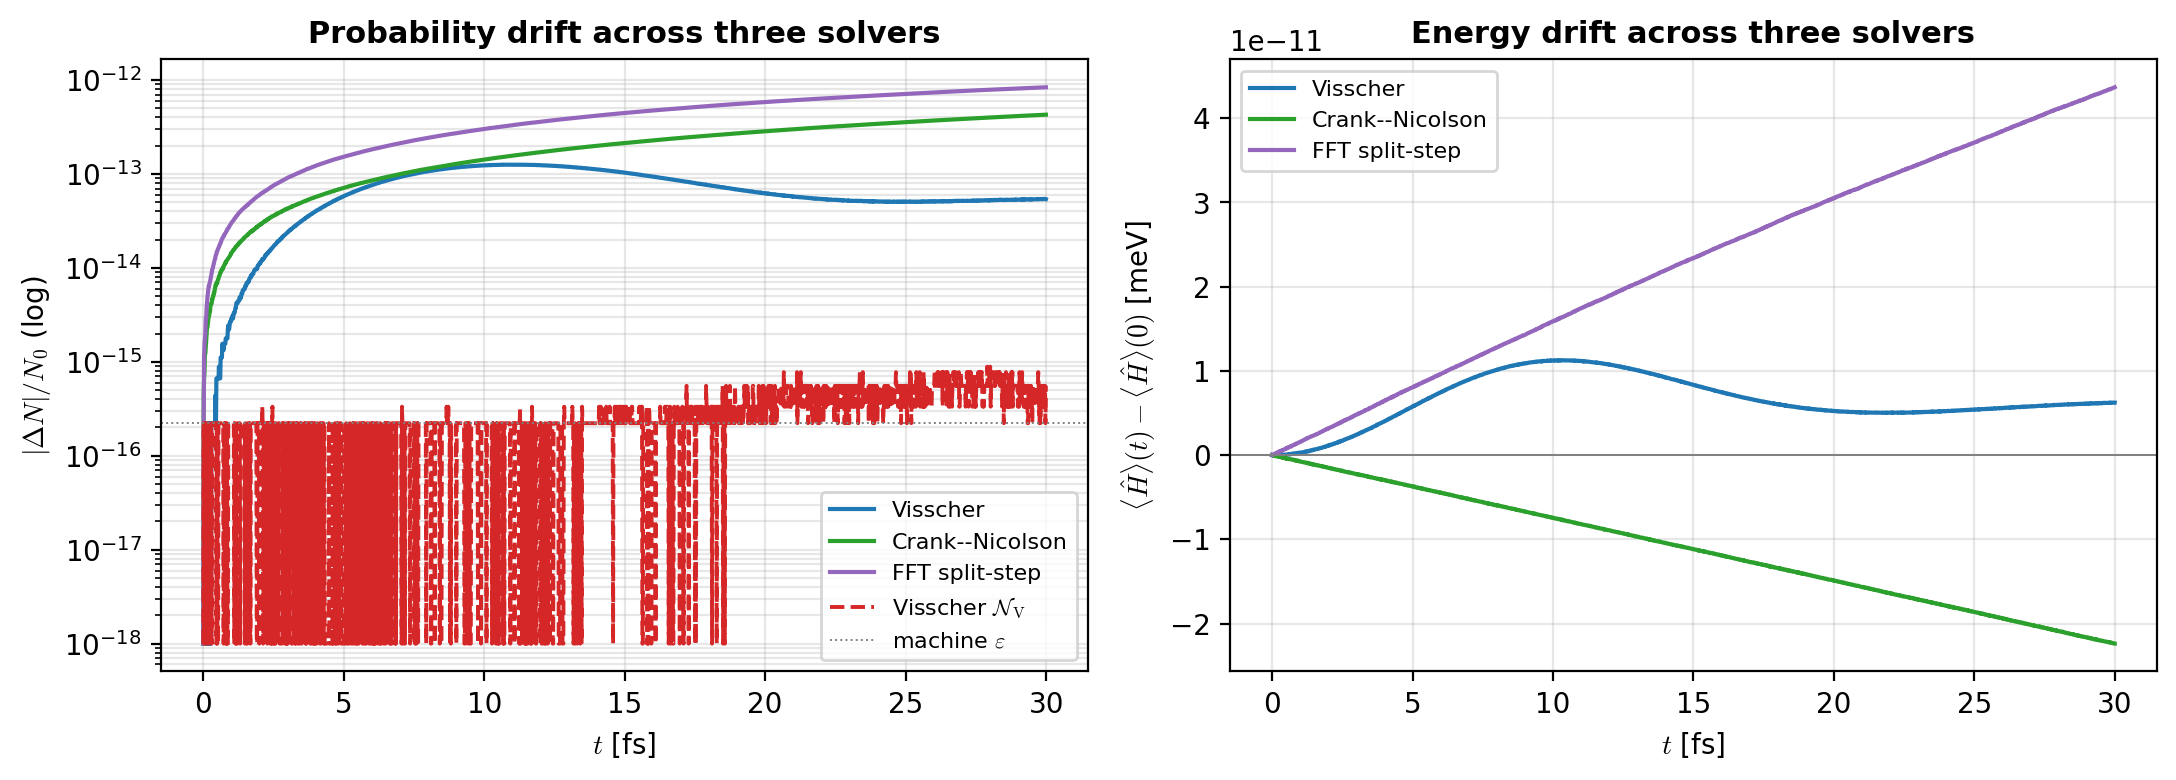)

**Logic?** This shows how Visscher is the best moethod out of the three where althought they all have total energy drift in the order of $10^{-11}$, Visccher converges while both Crank-Nicolson and FFT diverge in growth and decay resepctively. This deems Visscher as the ONLY trustworthy and reliable solver for the TDSE.

# Part II | Free Particle & Bound State

Here I simulate and analyze a free Gaussian wave packet and a simple harmonic oscillator in a coherent state.


## II.1 | Free Gaussian Wave Packet

A Gaussian with a momentum kick of $k_0 = \sqrt{2mE_0}/\hbar$ ($\sigma_0 = 2$ nm, $E_0 = 0.5$ eV) within a $V = 0$ enviorment (no disturbances). The wave should move at $v_g = \hbar k_0/m$ with spreading of the wave packet in space (increasing the full width half max) by $\sigma_0\sqrt{1+(\hbar t/2m\sigma_0^2)^2}$. Since there is nothing dynamically happening besides free space propagation over time, $\hat p$, $\hat H$, and $\mathcal N_{Visscher}$ should all STAY constant.

**Figure II.1a–b.** Free Gaussian wave packet ($\sigma_0 = 2$ nm, $E_0 = 0.5$ eV). Top: animation. Bottom: $|\psi(x,t)|^2$ heatmap.

![Figure II.1a–b.  Free Gaussian wave packet, $\sigma_0 = 2$ nm, $E_0 = 0.5$ eV.  *Top:* animated GIF showing the packet sliding along the group-velocity worldline while spreading at the analytic rate.  *Bottom:* still snapshot of the space-time heatmap $|\psi(x,t)|^2$ used in the source notebooks. (a)](figures/01_free_gaussian.gif)

![Figure II.1a–b.  Free Gaussian wave packet, $\sigma_0 = 2$ nm, $E_0 = 0.5$ eV.  *Top:* animated GIF showing the packet sliding along the group-velocity worldline while spreading at the analytic rate.  *Bottom:* still snapshot of the space-time heatmap $|\psi(x,t)|^2$ used in the source notebooks. (b)](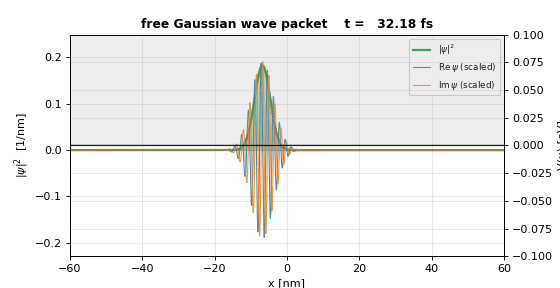)

**Figure II.1c.** Conservation diagnostics for the free Gaussian: norm, Visscher norm, $\langle T \rangle$, $\langle V \rangle$, $\langle H \rangle$, $\langle x \rangle$, $\langle p \rangle$, and $\sigma_x(t)$ vs. analytic.

![Figure II.1c.  Six-panel conservation diagnostics for the free Gaussian.  Norm, Visscher modified norm, $\langle T\rangle$, $\langle V\rangle$, $\langle H\rangle$, $\langle x\rangle$, $\langle p\rangle$ and $\sigma_x(t)$ are all monitored simultaneously and overlaid on the analytic predictions where those exist.](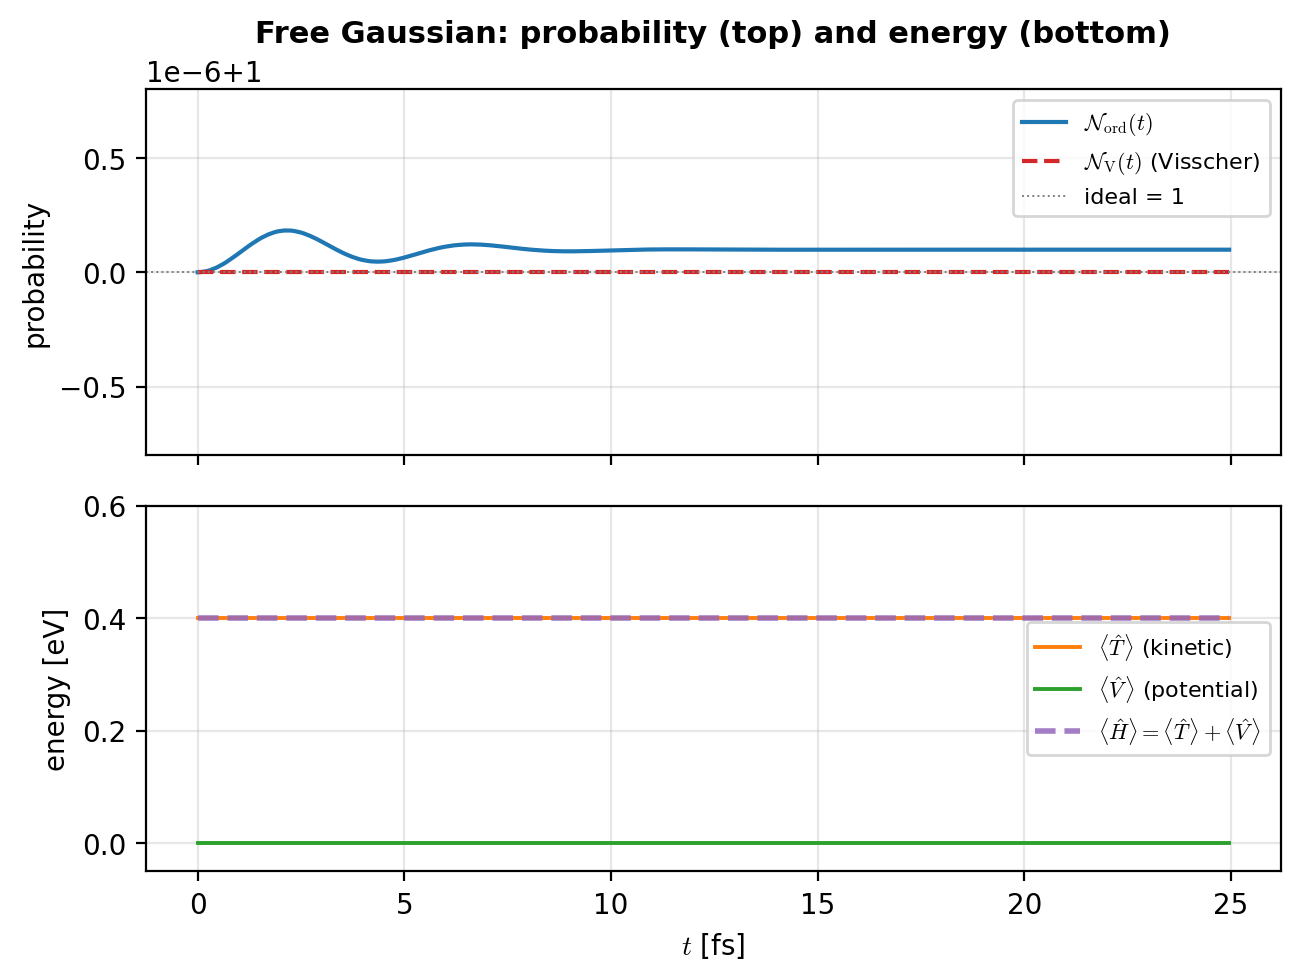)

**Results:** All of my predictions occured correctly with there being complete total energy conservation, no exchange between kinetic and potential energy occured as there was no dynamics nor collision that occured. As well as the probabilty (norm) was conserved for Visscher as expected with the ordinary norm having conservation but with an initial lost as the imaginary componet initially was not within its values (that is why its probability is greater as there is a mathmatical mismatch). Also, spreading of the wave packet occured, since the momentum is being well known, the position information is being lost slowly (relative to femto-seconds).

## II.2 | (Deleted) Deemed not needed.
## II.3 | Simple Harmonic Oscillator of a Coherent State

A coherent state is a wave that oscillates at the classical frequency *without spreading*. This to my knowlegde is quite literally the closest thing in quantum mechanics to a classical mechanics.

**Expected:** The position ($\hat x$) should track as $x_0\cos\omega t$ for many periods (cannot be for all of eternity as numerical simulations are not exact to analytical solutions). Total energy should stay constant (conserved) while $\hat T$ and $\hat V$ should exchange at a frequency of $2\omega$. There should be no drop off in thier amplitudes either.

**Figure II.3a–b.** Harmonic-oscillator coherent state, $\alpha = 2.5$. Gaussian density rocking between $\pm x_{\rm cl}$ at the classical period.

![Figure II.3a–b.  Harmonic-oscillator coherent state with $\alpha = 2.5$.  The Gaussian density rocks between $\pm x_{\rm cl}$ at the classical period $T = 2\pi/\omega$ without changing shape — the closest analogue in quantum mechanics of a classical harmonic oscillator. (a)](figures/01_coherent_state.gif)

![Figure II.3a–b.  Harmonic-oscillator coherent state with $\alpha = 2.5$.  The Gaussian density rocks between $\pm x_{\rm cl}$ at the classical period $T = 2\pi/\omega$ without changing shape — the closest analogue in quantum mechanics of a classical harmonic oscillator. (b)](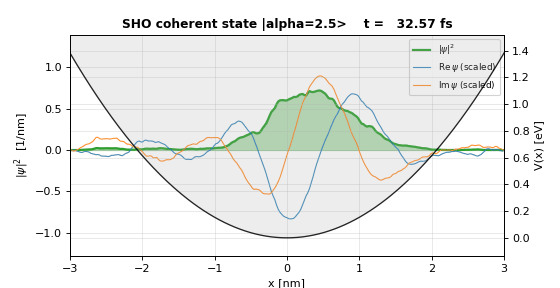)

**Figure II.3c.** Coherent-state diagnostics over three classical periods. Dashed grey: classical $x_{\rm cl}\cos\omega t$ overlay.

![Figure II.3c.  Coherent-state conservation diagnostics over three classical periods.  The grey dashed curve overlays the classical $x_{\rm cl}\cos\omega t$ on $\langle x\rangle(t)$; $\sigma_x(t)$ is flat at $\sigma_0$; $\langle T\rangle, \langle V\rangle$ each oscillate at $2\omega$, and their sum $\langle H\rangle$ is constant.](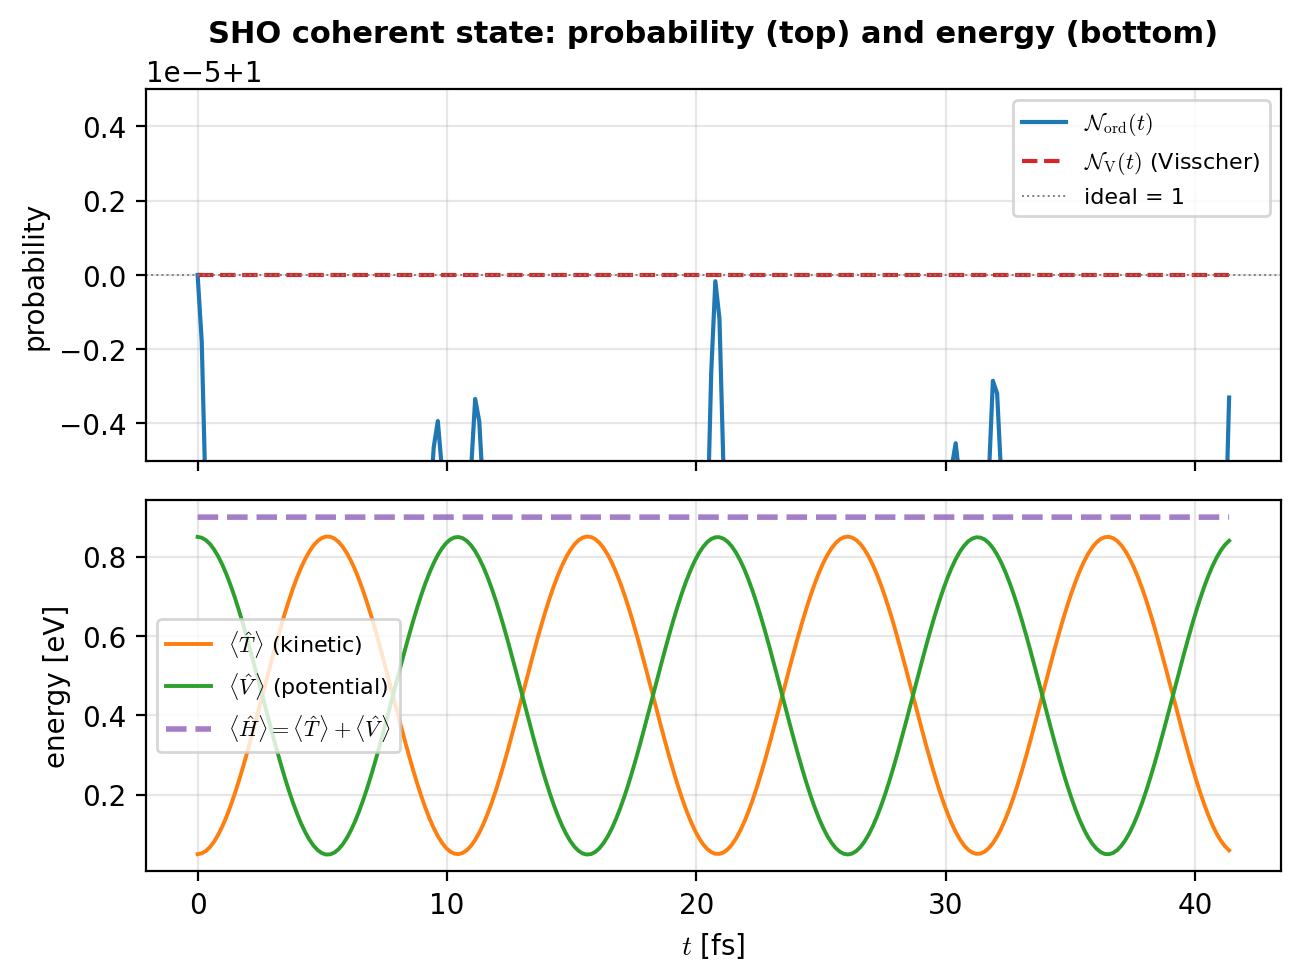)

**Results** A non-physical result occured. Although the probability AND total energy was conserved (constant). The noise/ripples/bumps are numerical artifacts. Kinetic and potential energies exchanged at the expected frequecy AND without amplitude losses. However, due to there being high momentum wavemodes (short wavelengths), informations is being severely lost as the $\Delta x$ is not capturing the shorter wavelengths entirely. This is not an issue of the staggered leapfrog, rather the use of a coarse spatial grid that only allows a finite number of wave modes (this value will always be finite due to computational limitations requiring discretization of space). This appears as a chaotic mess (which it is), and should be a prime example of what is not physical for a COHERENT state (a decoherent state **may** appear in a similar fashion, but I did not test that).

**Faulires?** Utilization of the nearest-nieghbor solver (3-point stencil) rather than a more distributed/smoother 5 or 7 point stencil causes drsatic information lost. The discrete eigenvalue spacing is not uniformly spread. The kinetic energy is being improperly solved by Visccher.

# Part III | Quantum Tunnelling

## III.1 | Finite Rectangular Potential Barrier

I sweep a wave of energy $E_0$ from a well below $V_0$ to a well above.

**Expected:** Partial tunneling to occur (told the AI to not give it enough potential energy to tunneling completely), probability of tunneling to match analytical results as found in Modern Physics course, and for both total energy and probability to be constant (conserved).

Tunnelling will exponentially amplify any error in $\kappa$ (wave mode), so if a previous test had hidden faults then this simulation is where that would be exposed (hopefully).

**Figure III.1a–c.** Rectangular barrier ($V_0 = 2$ eV, $a = 0.6$ nm). Top: animation. Middle: $|\psi(x,t)|^2$ heatmap. Bottom: $T(E)$ — wave-packet measurements vs. transfer matrix vs. Griffiths formula.

![Figure III.1a–c.  Rectangular barrier, $V_0 = 2$ eV, $a = 0.6$ nm.  *Top:* animation of a single-energy tunnelling event.  *Middle:* snapshot of the space-time heatmap.  *Bottom:* the headline $T(E)$ curve combining the analytic rectangular-barrier formula, the transfer-matrix reference, and the wave-packet measurements over six decades in $T$. (a)](figures/02_tunnelling.gif)

![Figure III.1a–c.  Rectangular barrier, $V_0 = 2$ eV, $a = 0.6$ nm.  *Top:* animation of a single-energy tunnelling event.  *Middle:* snapshot of the space-time heatmap.  *Bottom:* the headline $T(E)$ curve combining the analytic rectangular-barrier formula, the transfer-matrix reference, and the wave-packet measurements over six decades in $T$. (b)](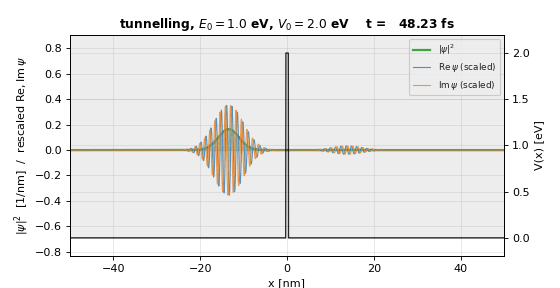)

![Figure III.1a–c.  Rectangular barrier, $V_0 = 2$ eV, $a = 0.6$ nm.  *Top:* animation of a single-energy tunnelling event.  *Middle:* snapshot of the space-time heatmap.  *Bottom:* the headline $T(E)$ curve combining the analytic rectangular-barrier formula, the transfer-matrix reference, and the wave-packet measurements over six decades in $T$. (c)](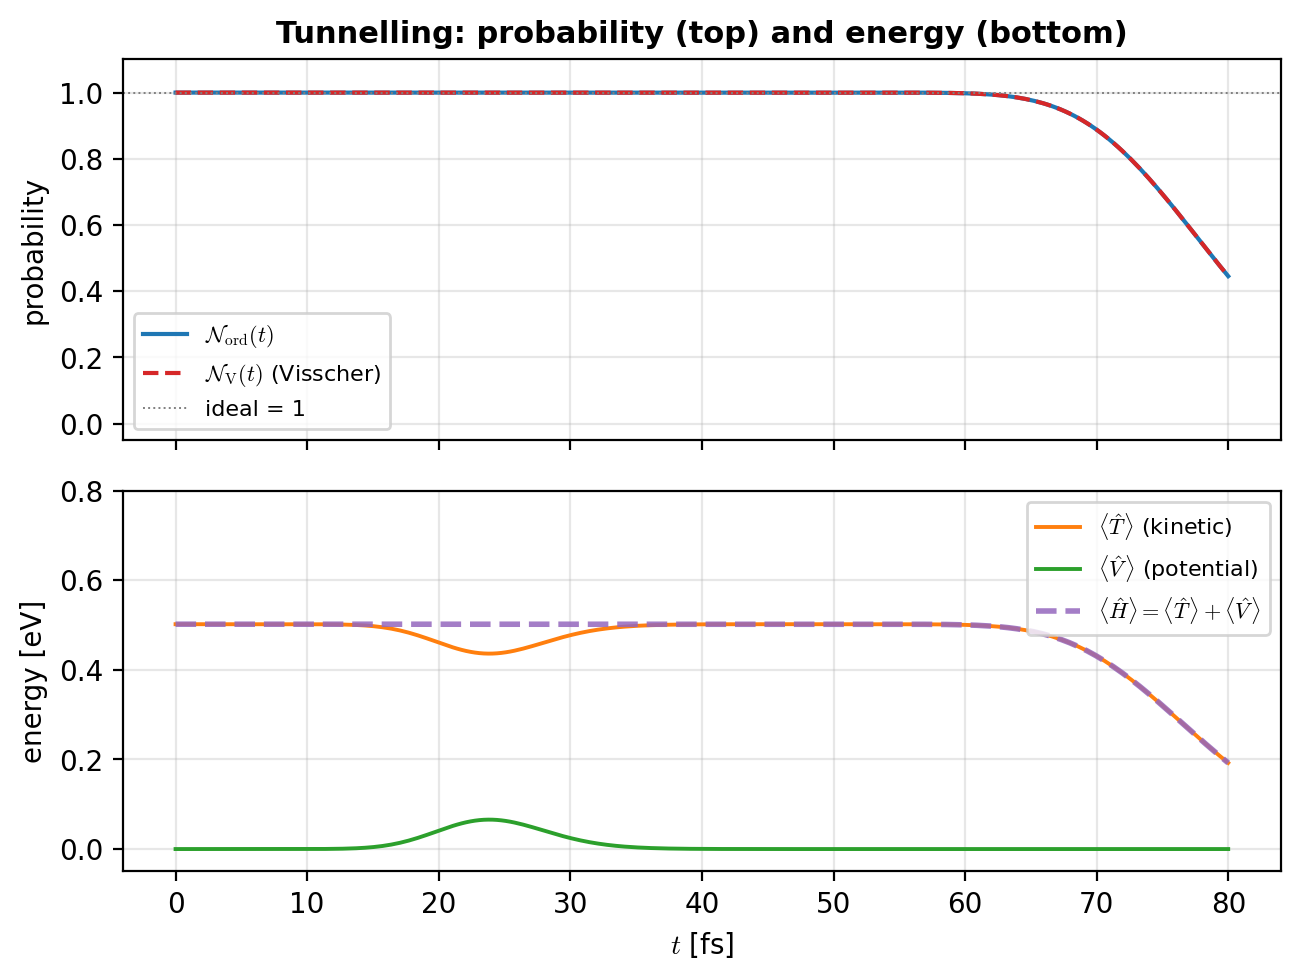)

**Results:** Partial tunneling occured succesfully and the wave packet did not smear onto the potential barrier into an infinte sandwhich (should never look like the delta function). Total energy and total probaility (the probabilities of the two waves as one total wave function) are constant, thus they are conserved. There is a fall off in both probability and total energy at the same time when the two wavepackets leave the frame which is expected due to the absorptive boundary conditions as hard wall boundaries would induce non phsyical reflections that may not be proccessable with my solver and $\Delta x$. A bump and drop for potential and kinetic energies resepectively occured as expected, as they occured at the same time when the tunneling occured (~23 fs). The two wave packets contain the same speed (vissually speaking), thus momentum conservation is obeyed.

I applied an absorptive boundary (essentially the same as only measuring within the visual window), which is both a fault and a blessing as it satisfies expectations of what should occur when the wave packet "leaves" the measurement frame.